In [1]:
# import necessary libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# set seaborn style
sns.set(style="whitegrid")

In [3]:
# Load the dataset
df = pd.read_csv("sample_data.csv")
df.head()

,age,income,test_score,purchases_per_month,department,has_degree,experience_years,response_time_ms,satisfaction_rating,employee_id
0,40,34099.73,21.9,7,Sales,True,8,34.69,6.8,1
1,33,38990.39,3.7,3,Sales,True,9,63.91,7.5,2
2,42,70985.98,10.8,5,Engineering,True,9,52.78,4.6,3
3,53,68561.47,33.9,8,Marketing,True,5,32.83,7.6,4
4,32,39893.41,80.3,6,Sales,False,8,6.50,8.6,5


In [4]:
# Examine the structure of the dataset
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  1000 non-null   int64  
 1   income               1000 non-null   float64
 2   test_score           1000 non-null   float64
 3   purchases_per_month  1000 non-null   int64  
 4   department           1000 non-null   object 
 5   has_degree           1000 non-null   bool   
 6   experience_years     1000 non-null   int64  
 7   response_time_ms     1000 non-null   float64
 8   satisfaction_rating  1000 non-null   float64
 9   employee_id          1000 non-null   int64  
dtypes: bool(1), float64(4), int64(4), object(1)
memory usage: 71.4+ KB


,age,income,test_score,purchases_per_month,experience_years,response_time_ms,satisfaction_rating,employee_id
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.097000,69902.105850,49.45020,5.939000,7.962000,32.623470,6.907800,500.500000
std,11.083431,46742.026203,28.89261,2.043393,2.708116,41.456749,2.192548,288.819436
min,18.000000,20000.000000,0.00000,0.000000,1.000000,1.240000,1.100000,1.000000
25%,27.000000,38934.655000,25.67500,5.000000,6.000000,10.372500,5.300000,250.750000
50%,35.000000,52758.680000,49.15000,6.000000,8.000000,20.095000,7.300000,500.500000
75%,42.000000,83687.877500,73.90000,7.000000,10.000000,39.257500,8.800000,750.250000
max,80.000000,318328.400000,99.80000,13.000000,16.000000,535.990000,10.000000,1000.000000


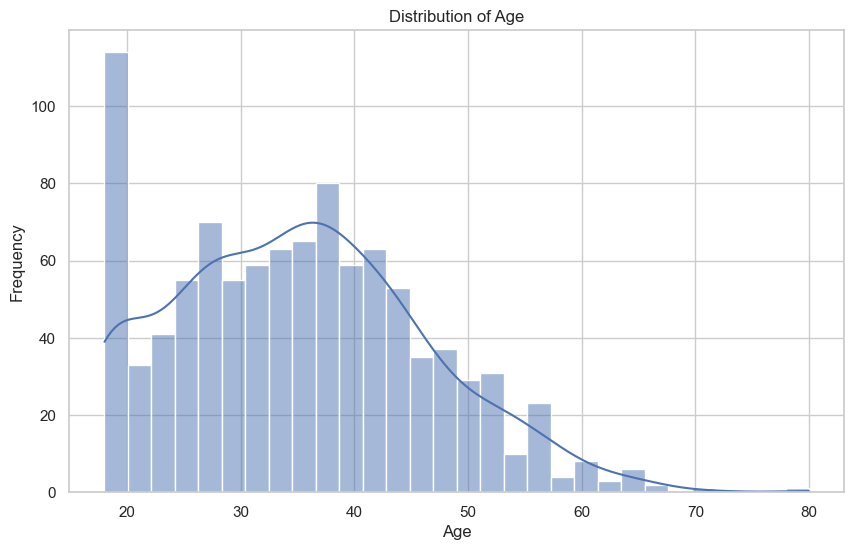

In [5]:
# Generate basic plots
plt.figure(figsize=(10, 6))
sns.histplot(df['age'], bins=30, kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

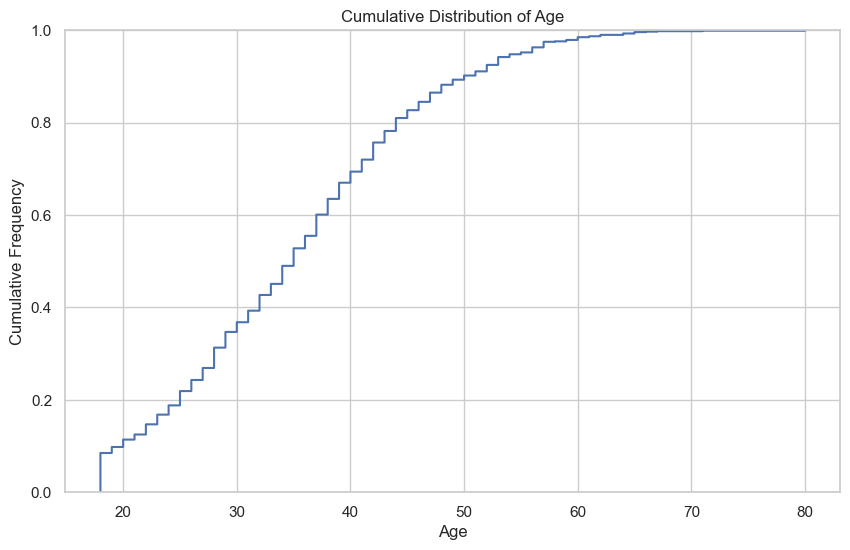

In [6]:
# Generate a cumulative distribution plot
plt.figure(figsize=(10, 6))
sns.ecdfplot(df['age'])
plt.title('Cumulative Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Cumulative Frequency')
plt.show()

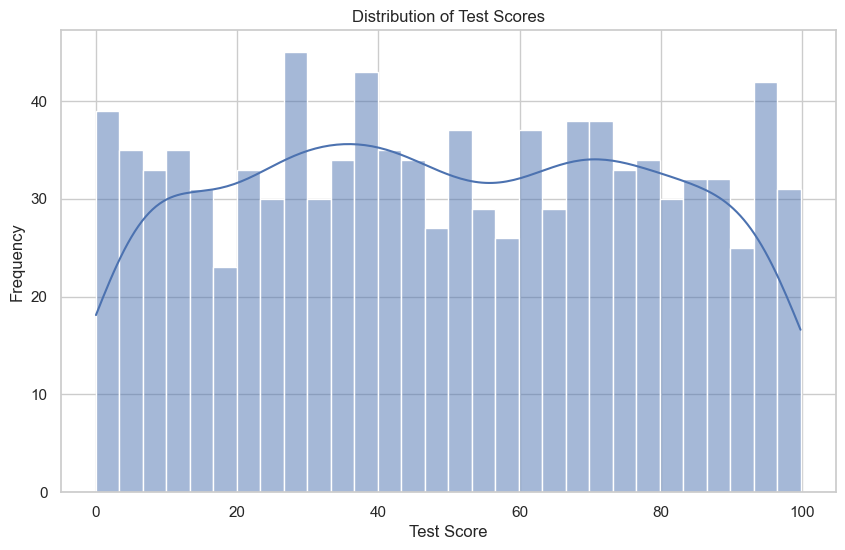

In [7]:
# Generate a histogram of test scores
plt.figure(figsize=(10, 6))
sns.histplot(df['test_score'], bins=30, kde=True)
plt.title('Distribution of Test Scores')
plt.xlabel('Test Score')
plt.ylabel('Frequency')
plt.show()

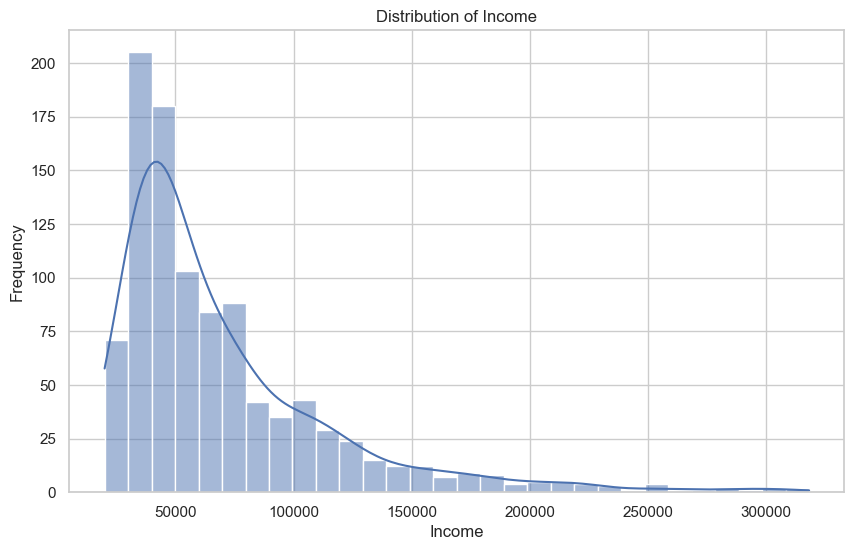

In [8]:
# Histogram of income
plt.figure(figsize=(10, 6))
sns.histplot(df['income'], bins=30, kde=True)
plt.title('Distribution of Income')
plt.xlabel('Income')
plt.ylabel('Frequency')
plt.show()

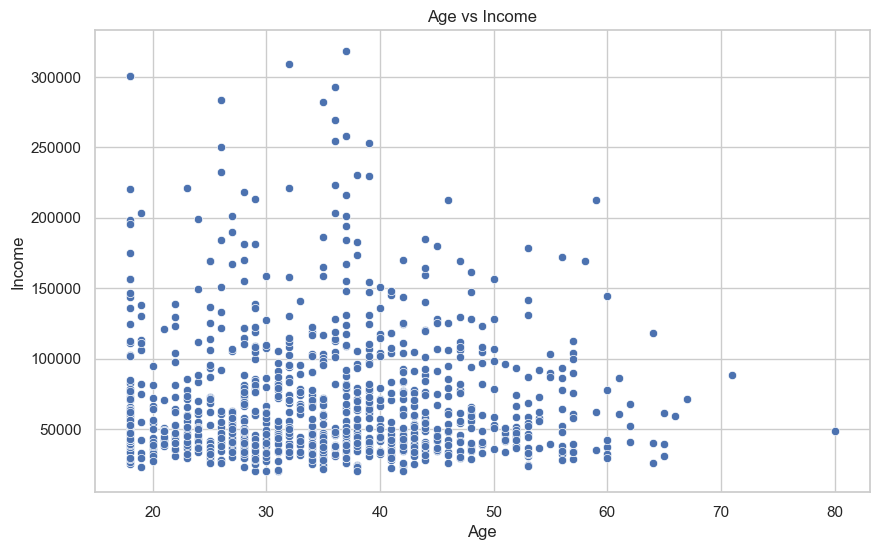

In [9]:
# compare age and income
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age', y='income', data=df)
plt.title('Age vs Income')
plt.xlabel('Age')
plt.ylabel('Income')
plt.show()

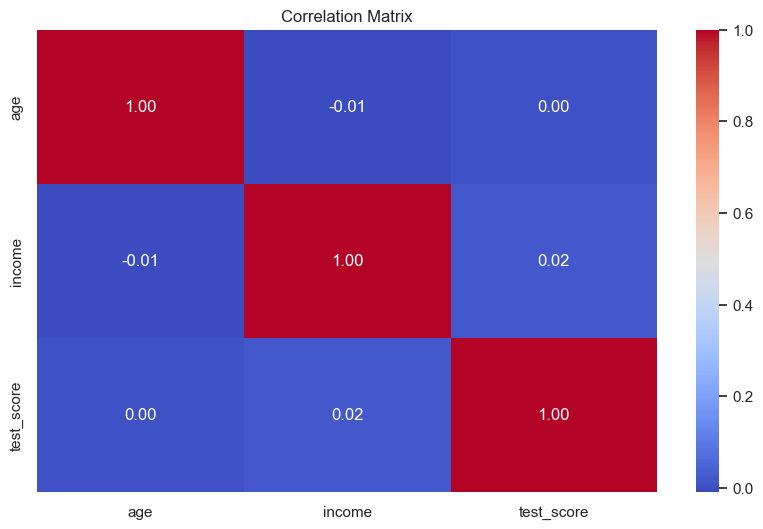

In [10]:
# Add a heatmap of correlations between age, income, and test_score
plt.figure(figsize=(10, 6))
correlation_matrix = df[['age', 'income', 'test_score']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

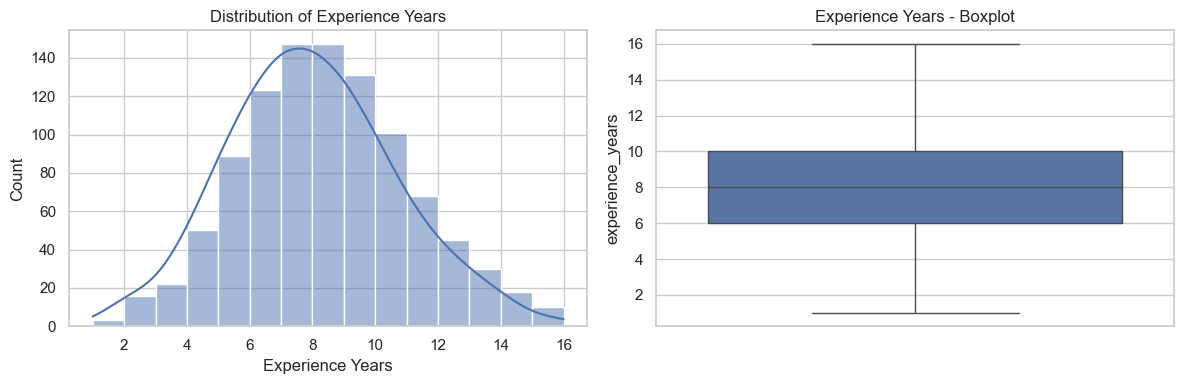

In [11]:
# === DISTRIBUTION ANALYSIS ===

# Experience years distribution
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['experience_years'], bins=15, kde=True)
plt.title('Distribution of Experience Years')
plt.xlabel('Experience Years')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['experience_years'])
plt.title('Experience Years - Boxplot')
plt.tight_layout()
plt.show()

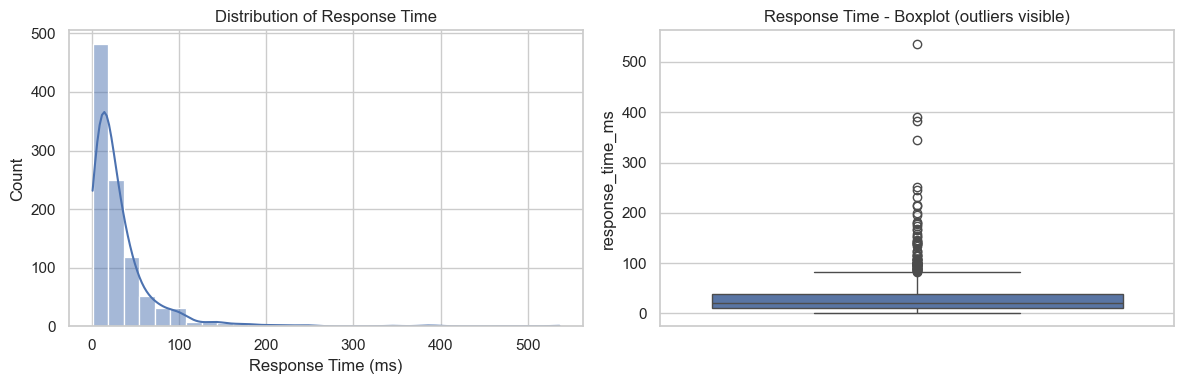

In [12]:
# Response time distribution (log-normal)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['response_time_ms'], bins=30, kde=True)
plt.title('Distribution of Response Time')
plt.xlabel('Response Time (ms)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['response_time_ms'])
plt.title('Response Time - Boxplot (outliers visible)')
plt.tight_layout()
plt.show()

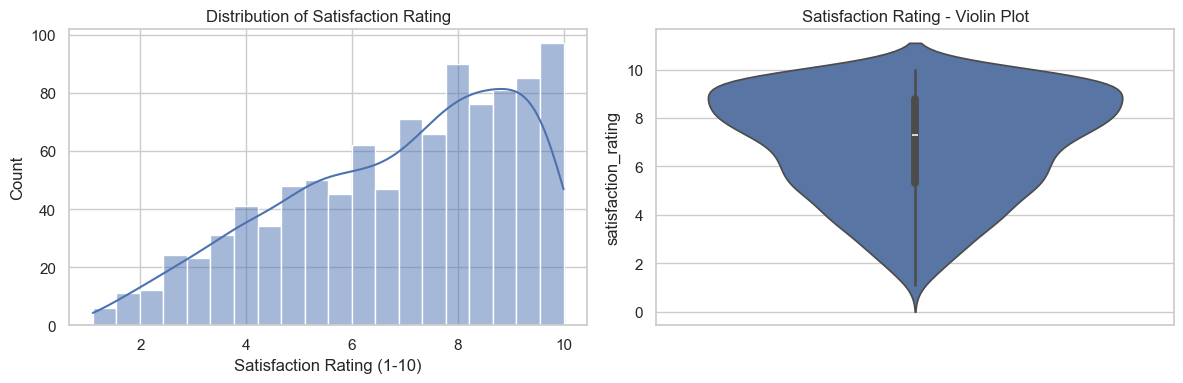

In [13]:
# Satisfaction rating distribution
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['satisfaction_rating'], bins=20, kde=True)
plt.title('Distribution of Satisfaction Rating')
plt.xlabel('Satisfaction Rating (1-10)')

plt.subplot(1, 2, 2)
sns.violinplot(y=df['satisfaction_rating'])
plt.title('Satisfaction Rating - Violin Plot')
plt.tight_layout()
plt.show()

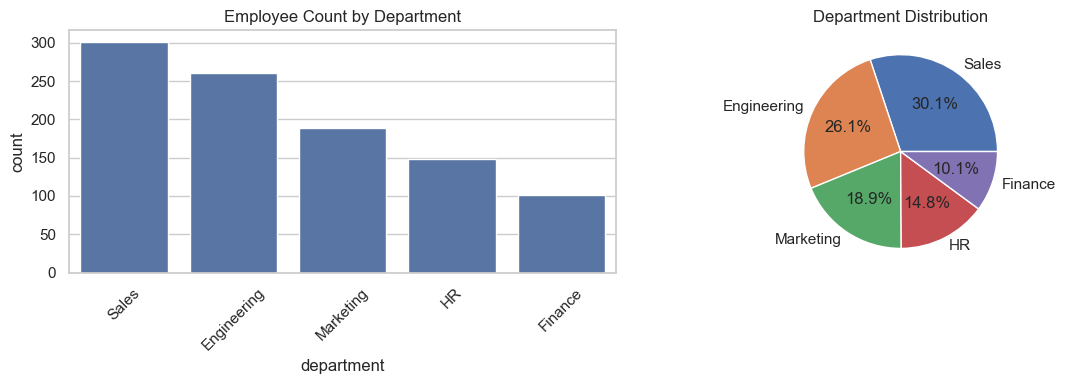

In [14]:
# === CATEGORICAL DATA ANALYSIS ===

# Department distribution
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='department', order=df['department'].value_counts().index)
plt.title('Employee Count by Department')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
department_counts = df['department'].value_counts()
plt.pie(department_counts.values, labels=department_counts.index, autopct='%1.1f%%')
plt.title('Department Distribution')
plt.tight_layout()
plt.show()

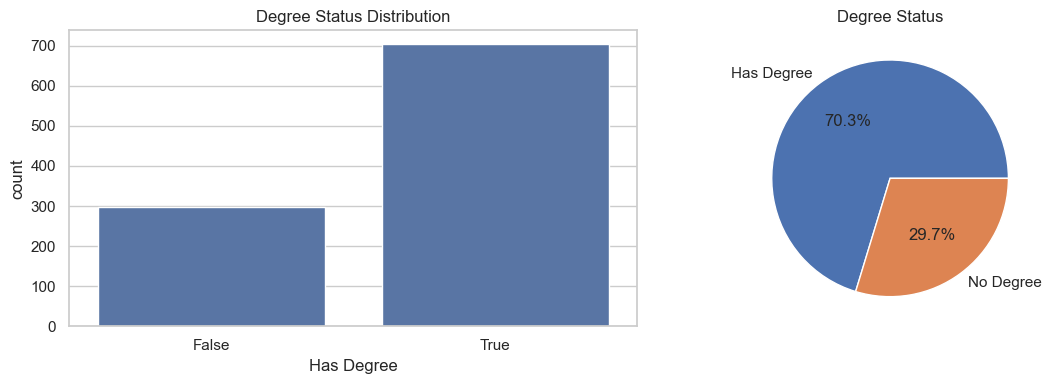

In [15]:
# Degree status distribution
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='has_degree')
plt.title('Degree Status Distribution')
plt.xlabel('Has Degree')

plt.subplot(1, 2, 2)
degree_counts = df['has_degree'].value_counts()
plt.pie(degree_counts.values, labels=['Has Degree', 'No Degree'], autopct='%1.1f%%')
plt.title('Degree Status')
plt.tight_layout()
plt.show()

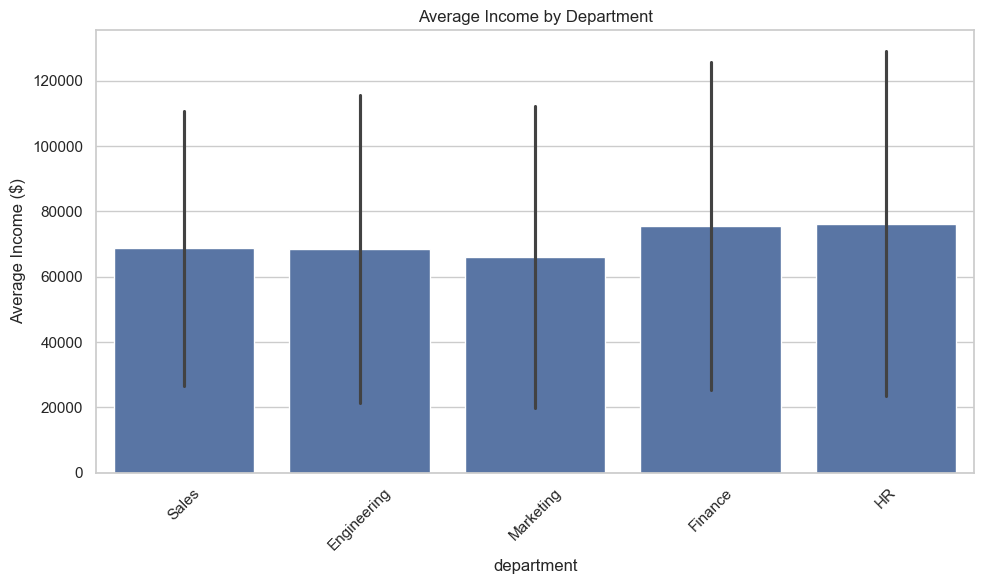

In [16]:
# Average income by department
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='department', y='income', errorbar='sd')
plt.title('Average Income by Department')
plt.xticks(rotation=45)
plt.ylabel('Average Income ($)')
plt.tight_layout()
plt.show()

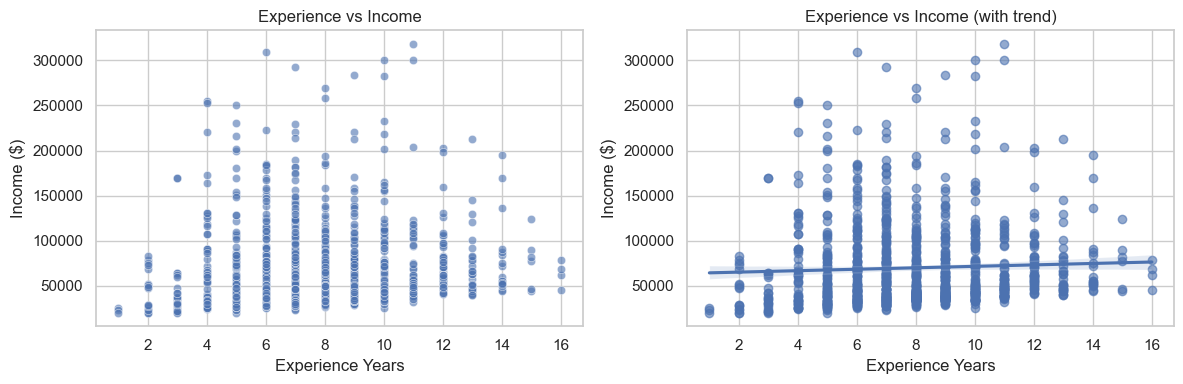

In [17]:
# === RELATIONSHIP ANALYSIS ===

# Experience vs Income with regression line
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='experience_years', y='income', alpha=0.6)
plt.title('Experience vs Income')
plt.xlabel('Experience Years')
plt.ylabel('Income ($)')

plt.subplot(1, 2, 2)
sns.regplot(data=df, x='experience_years', y='income', scatter_kws={'alpha':0.6})
plt.title('Experience vs Income (with trend)')
plt.xlabel('Experience Years')
plt.ylabel('Income ($)')
plt.tight_layout()
plt.show()

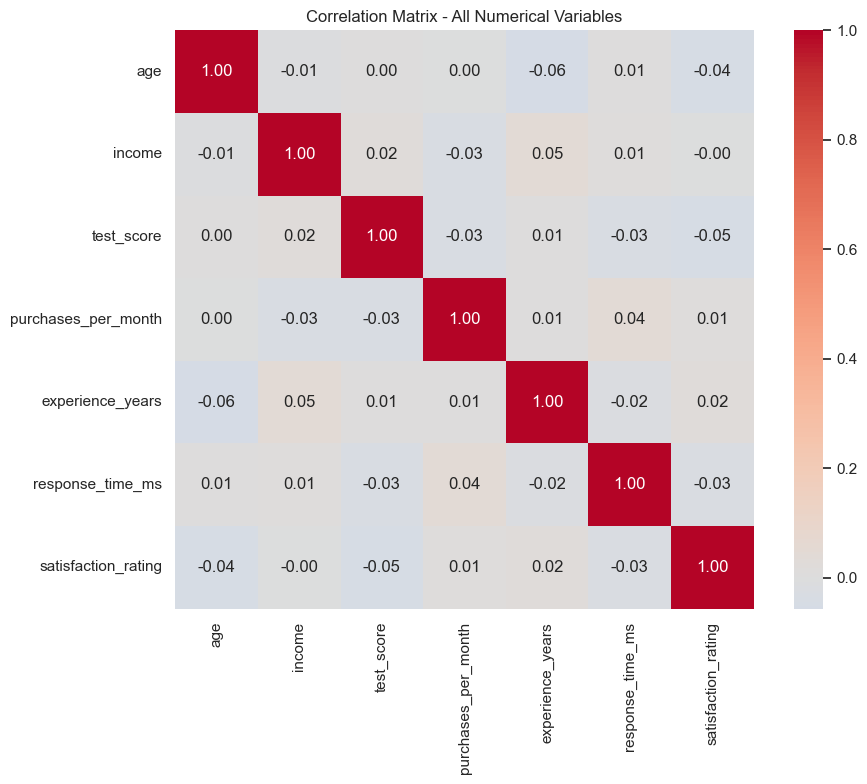

In [18]:
# Correlation matrix for all numerical variables
numerical_cols = ['age', 'income', 'test_score', 'purchases_per_month', 
                  'experience_years', 'response_time_ms', 'satisfaction_rating']

plt.figure(figsize=(10, 8))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, fmt='.2f')
plt.title('Correlation Matrix - All Numerical Variables')
plt.tight_layout()
plt.show()

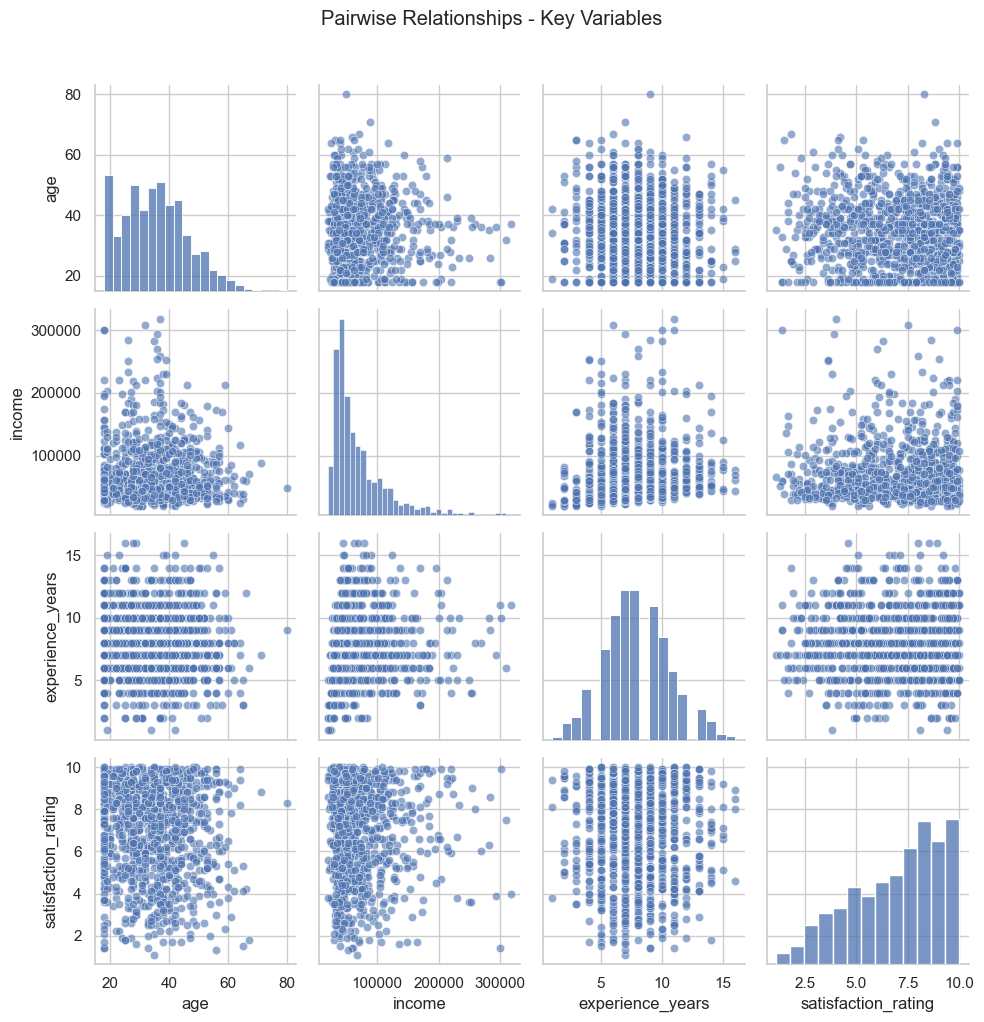

In [19]:
# Pairplot for key relationships
key_vars = ['age', 'income', 'experience_years', 'satisfaction_rating']
sns.pairplot(df[key_vars], diag_kind='hist', plot_kws={'alpha':0.6})
plt.suptitle('Pairwise Relationships - Key Variables', y=1.02)
plt.tight_layout()
plt.show()

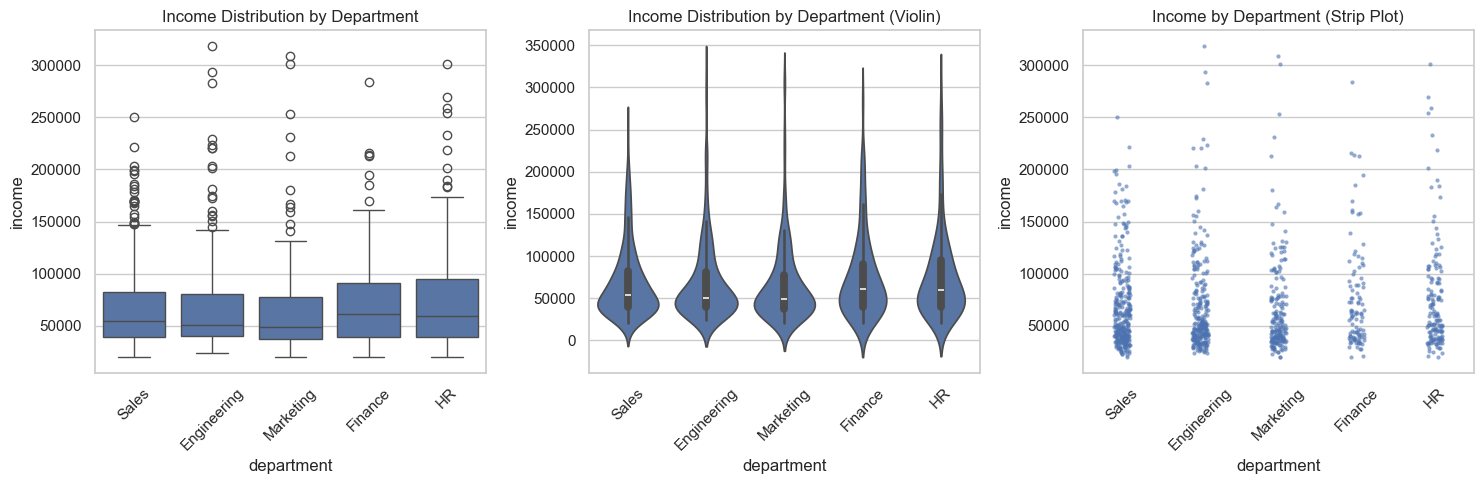

In [20]:
# === COMPARISON PLOTS ===

# Income by department - multiple views
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.boxplot(data=df, x='department', y='income')
plt.title('Income Distribution by Department')
plt.xticks(rotation=45)

plt.subplot(1, 3, 2)
sns.violinplot(data=df, x='department', y='income')
plt.title('Income Distribution by Department (Violin)')
plt.xticks(rotation=45)

plt.subplot(1, 3, 3)
sns.stripplot(data=df, x='department', y='income', alpha=0.6, size=3)
plt.title('Income by Department (Strip Plot)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

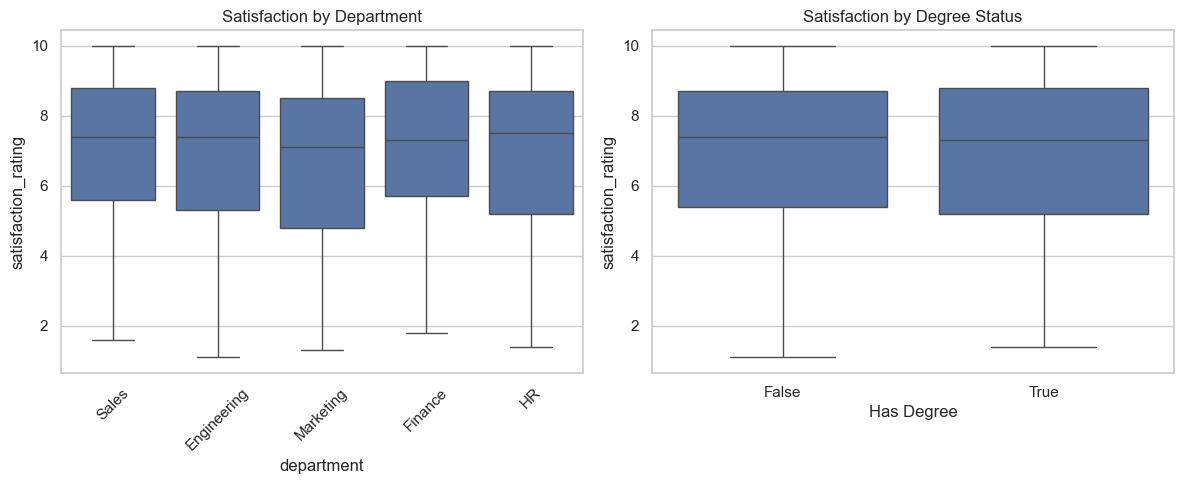

In [21]:
# Satisfaction by department and degree status
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='department', y='satisfaction_rating')
plt.title('Satisfaction by Department')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='has_degree', y='satisfaction_rating')
plt.title('Satisfaction by Degree Status')
plt.xlabel('Has Degree')
plt.tight_layout()
plt.show()

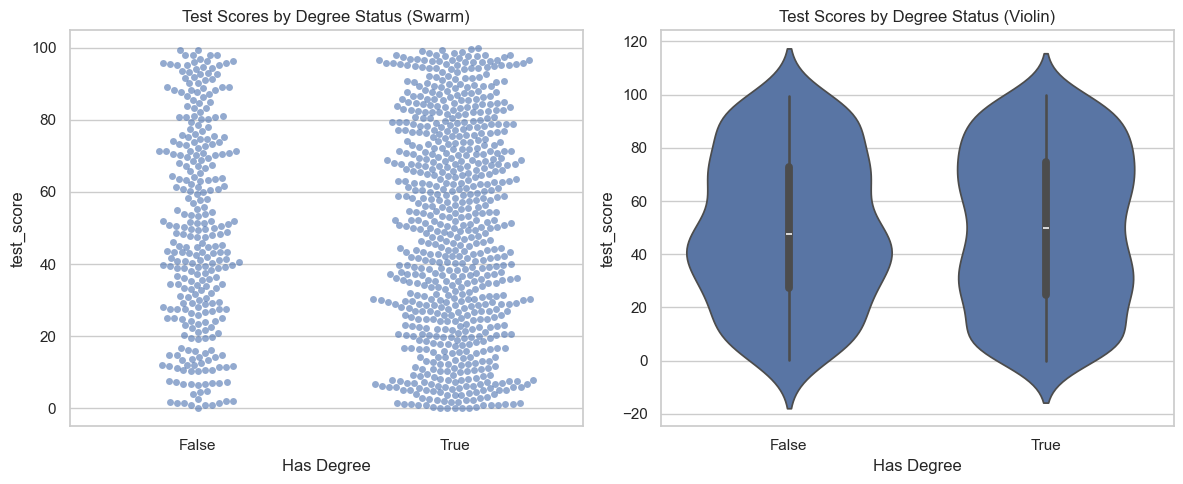

In [22]:
# Test scores by degree status
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.swarmplot(data=df, x='has_degree', y='test_score', alpha=0.6)
plt.title('Test Scores by Degree Status (Swarm)')
plt.xlabel('Has Degree')

plt.subplot(1, 2, 2)
sns.violinplot(data=df, x='has_degree', y='test_score')
plt.title('Test Scores by Degree Status (Violin)')
plt.xlabel('Has Degree')
plt.tight_layout()
plt.show()

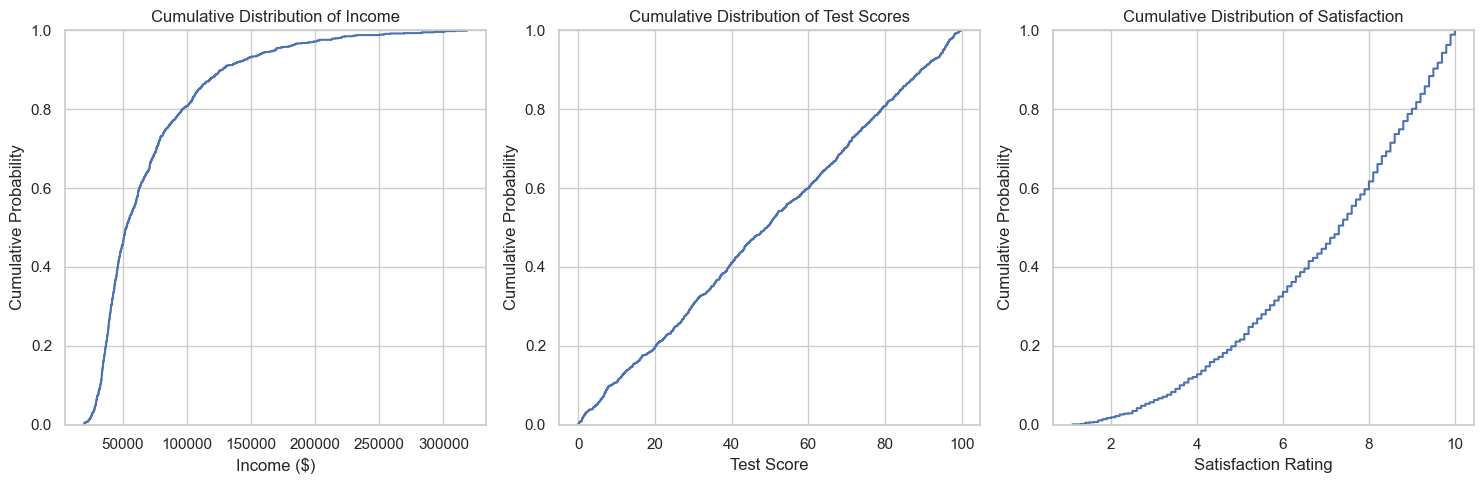

In [23]:
# === CUMULATIVE FREQUENCY PLOTS ===

# Multiple cumulative distributions
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.ecdfplot(data=df, x='income')
plt.title('Cumulative Distribution of Income')
plt.xlabel('Income ($)')
plt.ylabel('Cumulative Probability')

plt.subplot(1, 3, 2)
sns.ecdfplot(data=df, x='test_score')
plt.title('Cumulative Distribution of Test Scores')
plt.xlabel('Test Score')
plt.ylabel('Cumulative Probability')

plt.subplot(1, 3, 3)
sns.ecdfplot(data=df, x='satisfaction_rating')
plt.title('Cumulative Distribution of Satisfaction')
plt.xlabel('Satisfaction Rating')
plt.ylabel('Cumulative Probability')
plt.tight_layout()
plt.show()

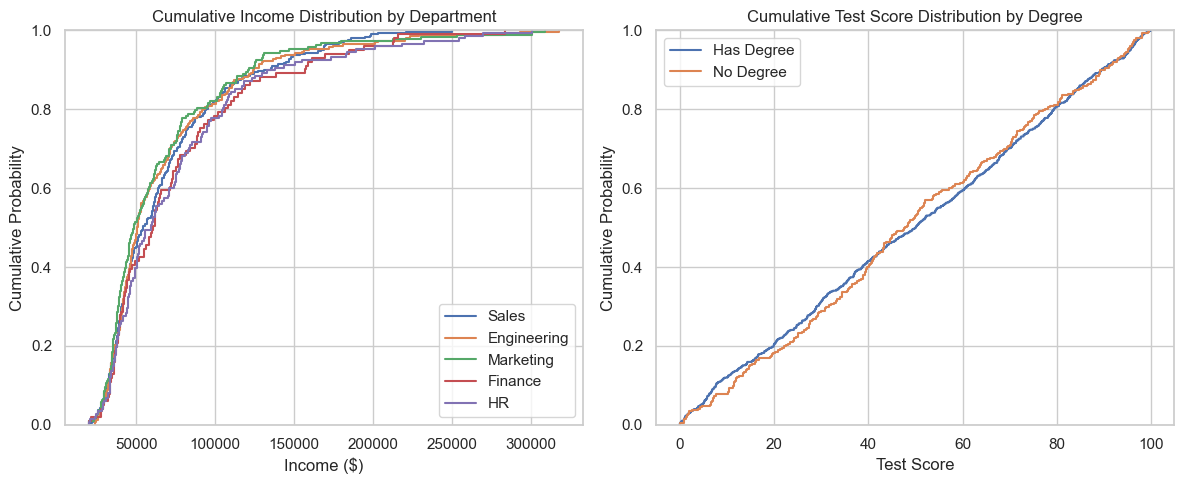

In [24]:
# Cumulative frequency by groups
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for dept in df['department'].unique():
    dept_data = df[df['department'] == dept]['income']
    sns.ecdfplot(data=dept_data, label=dept)
plt.title('Cumulative Income Distribution by Department')
plt.xlabel('Income ($)')
plt.ylabel('Cumulative Probability')
plt.legend()

plt.subplot(1, 2, 2)
for degree_status in [True, False]:
    degree_data = df[df['has_degree'] == degree_status]['test_score']
    label = 'Has Degree' if degree_status else 'No Degree'
    sns.ecdfplot(data=degree_data, label=label)
plt.title('Cumulative Test Score Distribution by Degree')
plt.xlabel('Test Score')
plt.ylabel('Cumulative Probability')
plt.legend()
plt.tight_layout()
plt.show()

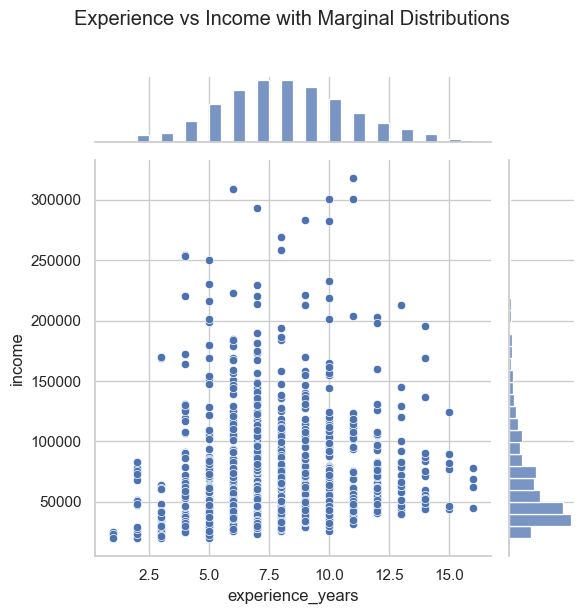

In [25]:
# === ADVANCED MULTI-VARIABLE PLOTS ===

# Joint plot with marginal distributions
sns.jointplot(data=df, x='experience_years', y='income', kind='scatter', 
              marginal_kws={'bins': 30})
plt.suptitle('Experience vs Income with Marginal Distributions', y=1.02)
plt.tight_layout()
plt.show()

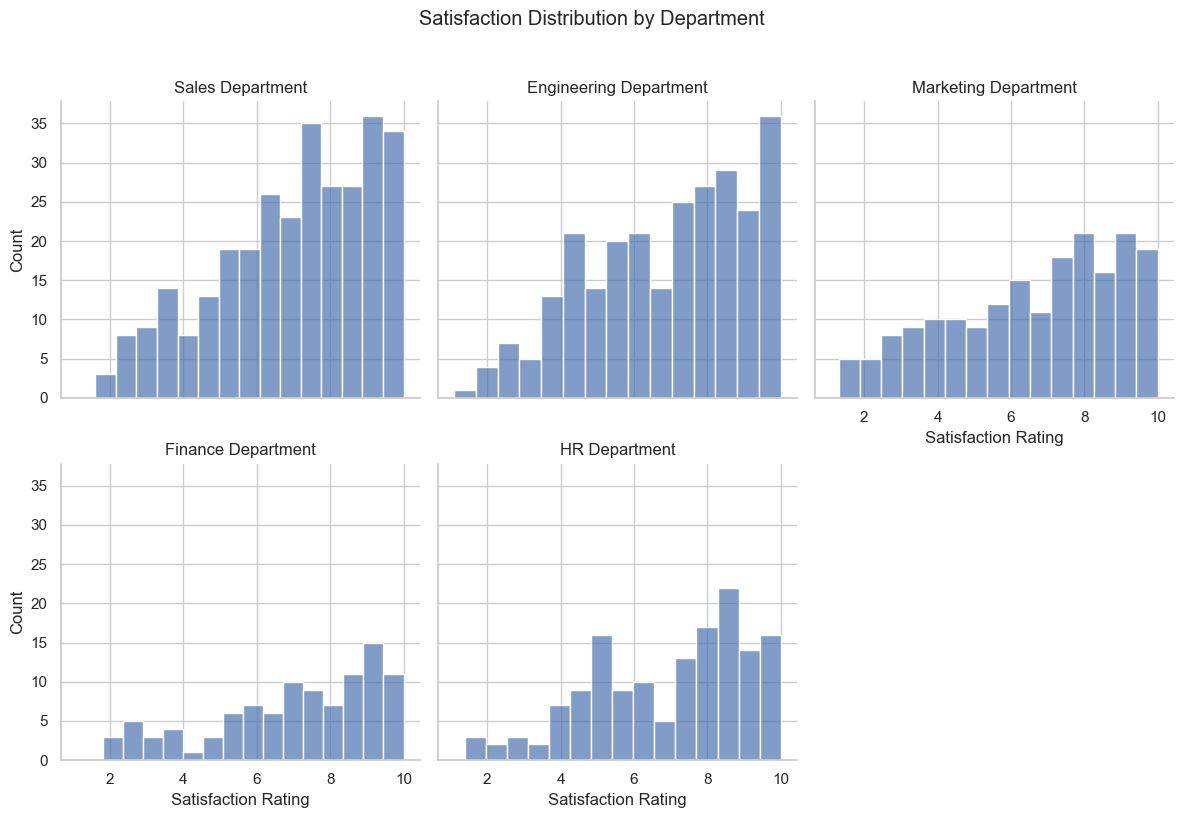

In [26]:
# FacetGrid for multiple plots by category
g = sns.FacetGrid(df, col='department', col_wrap=3, height=4)
g.map(sns.histplot, 'satisfaction_rating', bins=15, alpha=0.7)
g.set_axis_labels('Satisfaction Rating', 'Count')
g.set_titles('{col_name} Department')
plt.suptitle('Satisfaction Distribution by Department', y=1.02)
plt.tight_layout()
plt.show()